# Notebook 2 – Fire Incident Machine Learning
**Inputs:** the exports from *Notebook 1 – Data Prep* (`incidents_clean.csv`, `ml_daily_area_panel.csv`)

| # | Model task | Question answered | Target |
|---|---|---|---|
| A | Incident category classification | *If a fire occurs here / now / on this equipment, what category will it be?* | `fire_nature` |
| B | NLP text classification | *Classify a new free-text emergency report automatically* | `fire_nature`, `cause_category` |
| C | High-risk area prediction | *Which area is most likely to have the next fire?* | `fire_occurred` (daily × area) |

Algorithms compared: **Logistic Regression, Random Forest, XGBoost**.

> ⚠️ **No leakage:** Model A uses only information known **before/at ignition** (time, area, equipment, fuel, history).
> Response columns (agents used, extinguisher kg, who extinguished, etc.) are excluded because they are outcomes.

## 1. Setup

In [1]:
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, average_precision_score, brier_score_loss)
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# ---- CONFIG ----
DATA_DIR = Path(".")                  # folder holding Notebook 1 exports
OUT_DIR = Path("fire_ml_models")      # models, charts, predictions
OUT_DIR.mkdir(exist_ok=True)
(OUT_DIR / "charts").mkdir(exist_ok=True)
RANDOM_STATE = 42
TEST_START = "2026-07-01"             # time-based hold-out for the area-risk model

## 2. Load Notebook 1 exports

In [2]:
inc = pd.read_csv(DATA_DIR / "incidents_clean.csv", parse_dates=["incident_date", "call_datetime", "response_datetime"])
panel = pd.read_csv(DATA_DIR / "ml_daily_area_panel.csv", parse_dates=["date"])
inc.columns = inc.columns.str.replace("\ufeff", "")
panel.columns = panel.columns.str.replace("\ufeff", "")

print("Incidents :", inc.shape, "| period:", inc["incident_date"].min().date(), "→", inc["incident_date"].max().date())
print("Area panel:", panel.shape, "| fire-days:", int(panel["fire_occurred"].sum()))
inc["fire_nature"].value_counts().to_frame("count")

Incidents : (61, 85) | period: 2026-01-01 → 2026-10-02
Area panel: (6080, 23) | fire-days: 58


,count
fire_nature,
EQUIPMENT,44
BUILDING,10
3RD PARTY,5
BUSH/SCRAP,2


## 3. Model A – Predict incident category (`fire_nature`)
Rare classes with fewer than `MIN_CLASS` records are grouped so that cross-validation is possible.
With only ~61 records, evaluation uses **stratified k-fold cross-validation** (every incident is predicted once by a model that never saw it).

In [3]:
MIN_CLASS = 3
y_raw = inc["fire_nature"].copy()
rare = y_raw.value_counts()[lambda s: s < MIN_CLASS].index
y_a = y_raw.replace({c: "BUILDING" if c == "BUSH/SCRAP" else "OTHER" for c in rare})   # BUSH/SCRAP fires sat next to buildings/scrap – merged
print("Rare classes merged:", list(rare))
print(y_a.value_counts())

CAT_A = ["area", "zone", "equipment_type", "fuel_type", "operating_activity", "shift", "time_band", "season"]
NUM_A = ["hour_sin", "hour_cos", "month_sin", "month_cos", "day_of_week", "is_weekend",
         "hydrocarbon_involved", "hydrogen_involved", "contractor_involved", "is_flash_fire",
         "prior_incidents_area", "area_fires_prev_30d", "area_fires_prev_90d",
         "plant_fires_prev_7d", "plant_fires_prev_30d", "is_repeat_equipment"]
X_a = inc[CAT_A + NUM_A].copy()
X_a[CAT_A] = X_a[CAT_A].fillna("Unknown")

pre_a = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=1), CAT_A),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_A),
])

le_a = LabelEncoder().fit(y_a)
y_a_enc = le_a.transform(y_a)
n_splits = int(min(5, pd.Series(y_a).value_counts().min()))
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
print("CV folds:", n_splits)

Rare classes merged: ['BUSH/SCRAP']
fire_nature
EQUIPMENT    44
BUILDING     12
3RD PARTY     5
Name: count, dtype: int64
CV folds: 5


In [4]:
def make_models(n_classes):
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5),
        "Random Forest": RandomForestClassifier(n_estimators=400, max_depth=6, min_samples_leaf=1,
                                                class_weight="balanced", random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.08, subsample=0.9,
                                 colsample_bytree=0.8, eval_metric="mlogloss" if n_classes > 2 else "logloss",
                                 random_state=RANDOM_STATE, verbosity=0),
    }

def cv_evaluate(X, y_enc, pre, labels, cv):
    rows, preds, probas = [], {}, {}
    for name, mdl in make_models(len(labels)).items():
        pipe = Pipeline([("pre", pre), ("model", mdl)])
        fit_params = {}
        if name == "XGBoost":   # XGBoost has no class_weight -> use balanced sample weights
            fit_params = {"model__sample_weight": compute_sample_weight("balanced", y_enc)}
        proba = cross_val_predict(pipe, X, y_enc, cv=cv, method="predict_proba", params=fit_params)
        pred = proba.argmax(axis=1)
        preds[name], probas[name] = pred, proba
        rows.append({"model": name,
                     "accuracy": accuracy_score(y_enc, pred),
                     "balanced_accuracy": balanced_accuracy_score(y_enc, pred),
                     "f1_macro": f1_score(y_enc, pred, average="macro"),
                     "f1_weighted": f1_score(y_enc, pred, average="weighted")})
    res = pd.DataFrame(rows).sort_values("f1_macro", ascending=False).reset_index(drop=True)
    return res, preds, probas

res_a, preds_a, probas_a = cv_evaluate(X_a, y_a_enc, pre_a, le_a.classes_, cv)
baseline = pd.Series(y_a).value_counts(normalize=True).max()
print(f"Baseline (always predict majority class) accuracy = {baseline:.2f}")
res_a.round(3)

Baseline (always predict majority class) accuracy = 0.72


,model,accuracy,balanced_accuracy,f1_macro,f1_weighted
0,XGBoost,0.902,0.894,0.894,0.902
1,Random Forest,0.885,0.827,0.853,0.885
2,Logistic Regression,0.836,0.784,0.784,0.836


Best model A: XGBoost 

              precision    recall  f1-score   support

   3RD PARTY       1.00      1.00      1.00         5
    BUILDING       0.75      0.75      0.75        12
   EQUIPMENT       0.93      0.93      0.93        44

    accuracy                           0.90        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.90      0.90      0.90        61



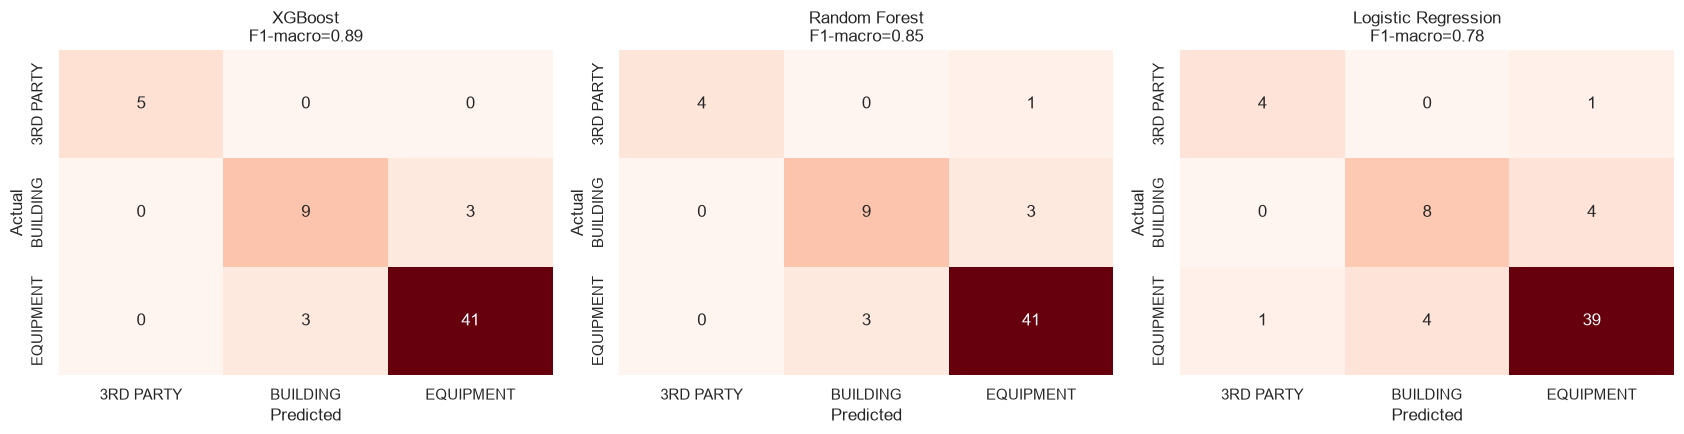

In [5]:
best_a = res_a.loc[0, "model"]
print("Best model A:", best_a, "\n")
print(classification_report(y_a_enc, preds_a[best_a], target_names=le_a.classes_, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, name in zip(axes, res_a["model"]):
    cm = confusion_matrix(y_a_enc, preds_a[name], labels=range(len(le_a.classes_)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", cbar=False, ax=ax,
                xticklabels=le_a.classes_, yticklabels=le_a.classes_)
    ax.set_title(f"{name}\nF1-macro={res_a.set_index('model').loc[name,'f1_macro']:.2f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig(OUT_DIR / "charts" / "A_confusion_matrices.png", dpi=130); plt.show()

### Feature importance – what drives the incident category?

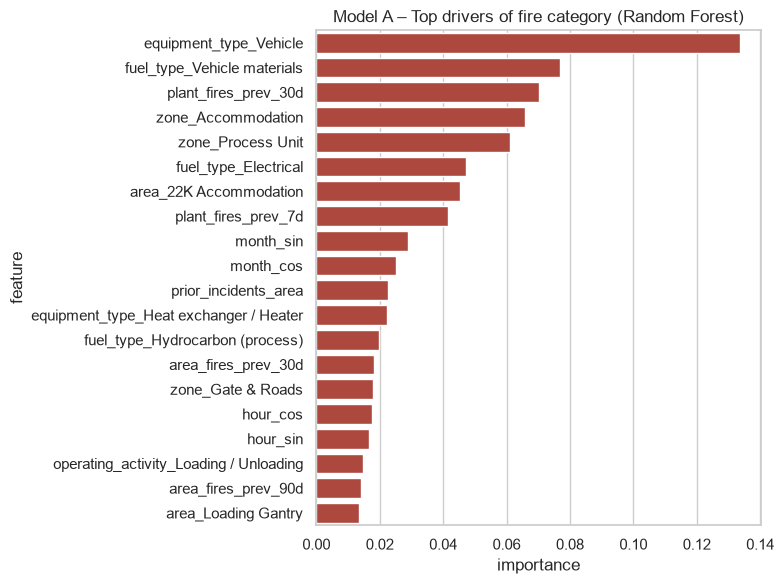

In [6]:
def fit_full(name, X, y_enc, pre, n_classes):
    pipe = Pipeline([("pre", pre), ("model", make_models(n_classes)[name])])
    kw = {"model__sample_weight": compute_sample_weight("balanced", y_enc)} if name == "XGBoost" else {}
    return pipe.fit(X, y_enc, **kw)

def importance_table(pipe, top=20):
    names = pipe.named_steps["pre"].get_feature_names_out()
    names = [n.split("__", 1)[1] for n in names]
    m = pipe.named_steps["model"]
    if hasattr(m, "feature_importances_"):
        imp = m.feature_importances_
    else:
        imp = np.abs(m.coef_).mean(axis=0)
    return (pd.DataFrame({"feature": names, "importance": imp})
              .sort_values("importance", ascending=False).head(top).reset_index(drop=True))

models_a = {n: fit_full(n, X_a, y_a_enc, pre_a, len(le_a.classes_)) for n in res_a["model"]}
imp_a = importance_table(models_a["Random Forest"])

plt.figure(figsize=(8, 6))
sns.barplot(data=imp_a, y="feature", x="importance", color="#C0392B")
plt.title("Model A – Top drivers of fire category (Random Forest)")
plt.tight_layout(); plt.savefig(OUT_DIR / "charts" / "A_feature_importance.png", dpi=130); plt.show()

## 4. Model B – NLP text classifier on the emergency description
TF-IDF (words + bigrams) on `emergency_details` + `location`. Useful for **auto-tagging new reports** as soon as they are typed in.

In [7]:
text = (inc["location_clean"].fillna("") + " " + inc["emergency_details"].fillna("")).str.lower()

def nlp_eval(y, target_name, min_class=3):
    y = y.copy()
    small = y.value_counts()[lambda s: s < min_class].index
    y = y.replace({c: "Other / Unknown" if target_name == "cause_category" else "OTHER" for c in small})
    small = y.value_counts()[lambda s: s < 2].index           # still too small -> merge into biggest class
    y = y.replace({c: y.value_counts().idxmax() for c in small})
    le = LabelEncoder().fit(y); y_enc = le.transform(y)
    k = int(min(5, pd.Series(y).value_counts().min()))
    cvt = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True, stop_words="english")
    rows, preds = [], {}
    for name, mdl in make_models(len(le.classes_)).items():
        pipe = Pipeline([("tfidf", tfidf), ("model", mdl)])
        kw = {"model__sample_weight": compute_sample_weight("balanced", y_enc)} if name == "XGBoost" else {}
        p = cross_val_predict(pipe, text, y_enc, cv=cvt, params=kw)
        preds[name] = p
        rows.append({"target": target_name, "model": name, "accuracy": accuracy_score(y_enc, p),
                     "balanced_accuracy": balanced_accuracy_score(y_enc, p),
                     "f1_macro": f1_score(y_enc, p, average="macro")})
    res = pd.DataFrame(rows).sort_values("f1_macro", ascending=False).reset_index(drop=True)
    best = res.loc[0, "model"]
    final = Pipeline([("tfidf", tfidf), ("model", make_models(len(le.classes_))[best])])
    kw = {"model__sample_weight": compute_sample_weight("balanced", y_enc)} if best == "XGBoost" else {}
    final.fit(text, y_enc, **kw)
    return res, final, le, y, preds[best]

res_nlp_nature, nlp_nature, le_nlp_nature, y_nlp_nature, p_nlp_nature = nlp_eval(inc["fire_nature"], "fire_nature")
res_nlp_cause, nlp_cause, le_nlp_cause, y_nlp_cause, p_nlp_cause = nlp_eval(inc["cause_category"], "cause_category")
res_nlp = pd.concat([res_nlp_nature, res_nlp_cause], ignore_index=True)
res_nlp.round(3)

,target,model,accuracy,balanced_accuracy,f1_macro
0,fire_nature,Logistic Regression,0.918,0.675,0.684
1,fire_nature,XGBoost,0.770,0.472,0.492
2,fire_nature,Random Forest,0.787,0.375,0.417
3,cause_category,Random Forest,0.672,0.584,0.624
4,cause_category,XGBoost,0.705,0.552,0.588
5,cause_category,Logistic Regression,0.623,0.568,0.567


In [8]:
# Top keywords per category (Logistic Regression coefficients)
lr_kw = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words="english")),
                  ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))])
lr_kw.fit(text, le_nlp_cause.transform(y_nlp_cause))
vocab = np.array(lr_kw.named_steps["tfidf"].get_feature_names_out())
coefs = lr_kw.named_steps["model"].coef_
kw_rows = []
for i, cls in enumerate(le_nlp_cause.classes_):
    idx = coefs[i].argsort()[::-1][:8] if coefs.shape[0] > 1 else coefs[0].argsort()[::-1][:8]
    kw_rows.append({"cause_category": cls, "top_keywords": ", ".join(vocab[idx])})
keywords_by_cause = pd.DataFrame(kw_rows)
keywords_by_cause

,cause_category,top_keywords
0,Cooking / Domestic appliance,"kitchen, kettle, burner, kitchen 22k, pot gas,..."
1,Electrical fault,"electrical, panel, rm electrical, room, rm, 22..."
2,Flange / Seal leak,"flange, exchanger, effluent, mhc, outlet, 121,..."
3,Hot surface / Soaked insulation,"insulation, oil, 112, condensed, vapour, emiss..."
4,Hot work / Maintenance activity,"job, ct, hot, hydrocarbon, cdu, hot job, surge..."
5,Other / Unknown,"vent, tt, rfcc, train, 01, burning, burning ca..."
6,Vehicle fault,"driven, driven mr, engine, compartment, mr, lo..."


In [9]:
def classify_report(description, location=""):
    # Classify a brand-new free-text fire report
    t = pd.Series([(location + " " + description).lower()])
    nat_p = nlp_nature.predict_proba(t)[0]
    cau_p = nlp_cause.predict_proba(t)[0]
    return {"predicted_fire_nature": le_nlp_nature.classes_[nat_p.argmax()],
            "nature_confidence": round(float(nat_p.max()), 2),
            "predicted_cause": le_nlp_cause.classes_[cau_p.argmax()],
            "cause_confidence": round(float(cau_p.max()), 2)}

demo = [
    ("Fire from the outlet flange of effluent exchanger 121-EE-1004 due to hydrocarbon leak", "MHC"),
    ("Electrical fire in the toilet of a room, smoke seen from the panel", "22K Block M-03"),
    ("Engine compartment of a truck caught fire at the gate", "Main Gate"),
]
pd.DataFrame([{"location": l, "description": d, **classify_report(d, l)} for d, l in demo])

,location,description,predicted_fire_nature,nature_confidence,predicted_cause,cause_confidence
0,MHC,Fire from the outlet flange of effluent exchan...,EQUIPMENT,0.48,Flange / Seal leak,0.52
1,22K Block M-03,"Electrical fire in the toilet of a room, smoke...",BUILDING,0.45,Electrical fault,0.37
2,Main Gate,Engine compartment of a truck caught fire at t...,3RD PARTY,0.41,Vehicle fault,0.33


## 5. Model C – High-risk area prediction (daily × area)
Target `fire_occurred` = 1 if the area had ≥1 fire that day. Features are **lagged history only** + calendar.
Validation is **time-based**: train on data before `TEST_START`, test on the later period (how it would be used in real life).
Fires are rare (~1 % of rows) → metrics are **ROC-AUC, PR-AUC and Top-K hit-rate** (was the actual fire area in the model's top-K list that day?).

In [10]:
# Zone (not individual area) is used as the category: most areas have only 1-2 fires, so
# area one-hot columns would overfit. Area history enters through the numeric lag features.
CAT_C = ["zone"]
NUM_C = ["area_fires_prev_30d", "area_fires_prev_90d", "area_cum_fires_before", "area_fire_rate",
         "log_days_since", "ever_had_fire", "plant_fires_prev_7d", "plant_fires_prev_30d", "is_weekend"]

def add_derived(df):
    df["days_since_last_area_fire"] = df["days_since_last_area_fire"].clip(upper=365)
    df["log_days_since"] = np.log1p(df["days_since_last_area_fire"])
    df["ever_had_fire"] = (df["area_cum_fires_before"] > 0).astype(int)
    df["area_fire_rate"] = df["area_cum_fires_before"] / df["date"].dt.dayofyear   # fires per day so far
    return df
panel = add_derived(panel)

train = panel[panel["date"] < TEST_START].copy()
test = panel[panel["date"] >= TEST_START].copy()
print(f"Train rows {len(train):,} (fires {int(train.fire_occurred.sum())}) | Test rows {len(test):,} (fires {int(test.fire_occurred.sum())})")

pre_c = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_C),
    ("num", StandardScaler(), NUM_C),
])

models_c_def = {
    # no class re-weighting here -> probabilities stay realistic (needed for the 30-day risk %)
    "Logistic Regression": LogisticRegression(max_iter=3000, C=0.3),
    "Random Forest": RandomForestClassifier(n_estimators=400, max_depth=4, min_samples_leaf=20,
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.9,
                             eval_metric="logloss", random_state=RANDOM_STATE, verbosity=0),
}

def topk_hit_rate(df, score_col, k):
    # Share of fire-days where the burning area was in the model's top-k areas that day
    hits, total = 0, 0
    for d, g in df.groupby("date"):
        if g["fire_occurred"].sum() == 0:
            continue
        top = set(g.nlargest(k, score_col)["area"])
        fired = set(g.loc[g["fire_occurred"] == 1, "area"])
        hits += len(top & fired); total += len(fired)
    return hits / total if total else np.nan

rows, fitted_c = [], {}
for name, mdl in models_c_def.items():
    pipe = Pipeline([("pre", pre_c), ("model", mdl)]).fit(train[CAT_C + NUM_C], train["fire_occurred"])
    fitted_c[name] = pipe
    test[f"p_{name}"] = pipe.predict_proba(test[CAT_C + NUM_C])[:, 1]
    rows.append({"model": name,
                 "ROC_AUC": roc_auc_score(test["fire_occurred"], test[f"p_{name}"]),
                 "PR_AUC": average_precision_score(test["fire_occurred"], test[f"p_{name}"]),
                 "Top3_hit_rate": topk_hit_rate(test, f"p_{name}", 3),
                 "Top5_hit_rate": topk_hit_rate(test, f"p_{name}", 5)})

# naive baseline: rank by fires in last 90 days
test["p_Baseline (90d history)"] = test["area_fires_prev_90d"] + 0.01 * test["area_fire_rate"]
rows.append({"model": "Baseline (90d history)",
             "ROC_AUC": roc_auc_score(test["fire_occurred"], test["p_Baseline (90d history)"]),
             "PR_AUC": average_precision_score(test["fire_occurred"], test["p_Baseline (90d history)"]),
             "Top3_hit_rate": topk_hit_rate(test, "p_Baseline (90d history)", 3),
             "Top5_hit_rate": topk_hit_rate(test, "p_Baseline (90d history)", 5)})
res_c = pd.DataFrame(rows).sort_values("ROC_AUC", ascending=False).reset_index(drop=True)
print("Random chance PR-AUC ≈", round(test["fire_occurred"].mean(), 4), "| random Top-3 hit-rate ≈", round(3 / panel["area"].nunique(), 2))
res_c.round(3)

Train rows 3,620 (fires 40) | Test rows 2,460 (fires 18)
Random chance PR-AUC ≈ 0.0073 | random Top-3 hit-rate ≈ 0.15


,model,ROC_AUC,PR_AUC,Top3_hit_rate,Top5_hit_rate
0,Logistic Regression,0.596,0.021,0.333,0.444
1,Random Forest,0.583,0.017,0.222,0.444
2,Baseline (90d history),0.575,0.020,0.389,0.444
3,XGBoost,0.563,0.019,0.167,0.278


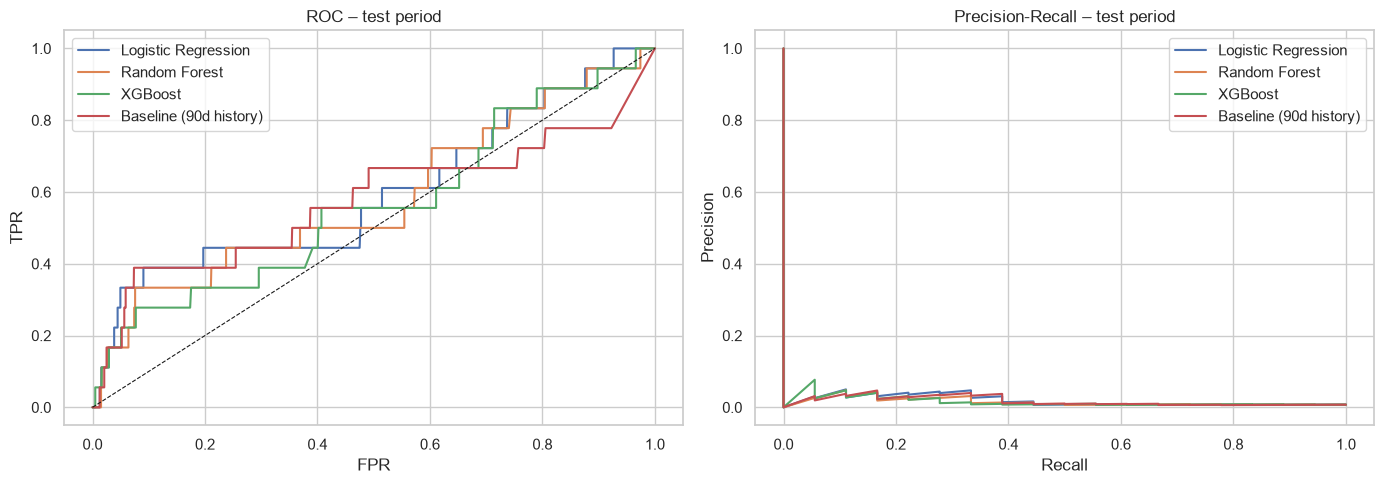

In [11]:
from sklearn.metrics import roc_curve, precision_recall_curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in list(models_c_def) + ["Baseline (90d history)"]:
    fpr, tpr, _ = roc_curve(test["fire_occurred"], test[f"p_{name}"])
    pr, rc, _ = precision_recall_curve(test["fire_occurred"], test[f"p_{name}"])
    axes[0].plot(fpr, tpr, label=name); axes[1].plot(rc, pr, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0].set_title("ROC – test period"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[1].set_title("Precision-Recall – test period"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
for a in axes: a.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "charts" / "C_roc_pr.png", dpi=130); plt.show()

### Refit on ALL data and score the next 30 days → area risk ranking

In [12]:
best_c = res_c[res_c["model"] != "Baseline (90d history)"].iloc[0]["model"]
print("Best area-risk model:", best_c)
final_c = Pipeline([("pre", pre_c), ("model", models_c_def[best_c].__class__(**models_c_def[best_c].get_params()))])
final_c.fit(panel[CAT_C + NUM_C], panel["fire_occurred"])

# also keep an ensemble (mean of all 3) – more stable with small data
final_all = {n: Pipeline([("pre", pre_c), ("model", m.__class__(**m.get_params()))]).fit(panel[CAT_C + NUM_C], panel["fire_occurred"])
             for n, m in models_c_def.items()}

HORIZON = 30
last_date = panel["date"].max()
hist = panel[["date", "area", "fire_count"]].copy()
zone_map = panel.drop_duplicates("area").set_index("area")["zone"]
plant_daily = hist.groupby("date")["fire_count"].sum()

future_rows = []
for area in panel["area"].unique():
    s = hist[hist["area"] == area].set_index("date")["fire_count"]
    fire_dates = s[s > 0].index
    for h in range(1, HORIZON + 1):
        d = last_date + pd.Timedelta(days=h)
        past = s[s.index < d]
        row = {"date": d, "area": area, "zone": zone_map[area],
               "is_weekend": int(d.dayofweek >= 5),
               "month_sin": np.sin(2 * np.pi * d.month / 12), "month_cos": np.cos(2 * np.pi * d.month / 12),
               "dow_sin": np.sin(2 * np.pi * d.dayofweek / 7), "dow_cos": np.cos(2 * np.pi * d.dayofweek / 7),
               "area_cum_fires_before": past.sum(),
               "plant_fires_prev_7d": plant_daily[plant_daily.index >= d - pd.Timedelta(days=7)].sum(),
               "plant_fires_prev_30d": plant_daily[plant_daily.index >= d - pd.Timedelta(days=30)].sum()}
        for w in [7, 14, 30, 60, 90]:
            row[f"area_fires_prev_{w}d"] = past[past.index >= d - pd.Timedelta(days=w)].sum()
        row["days_since_last_area_fire"] = min(365, (d - fire_dates.max()).days) if len(fire_dates) else 365
        row["log_days_since"] = np.log1p(row["days_since_last_area_fire"])
        row["ever_had_fire"] = int(row["area_cum_fires_before"] > 0)
        row["area_fire_rate"] = row["area_cum_fires_before"] / d.dayofyear
        future_rows.append(row)
future = pd.DataFrame(future_rows)
for n, p in final_all.items():
    future[f"p_{n}"] = p.predict_proba(future[CAT_C + NUM_C])[:, 1]
future["p_ensemble"] = future[[f"p_{n}" for n in final_all]].mean(axis=1)

area_risk = (future.groupby(["area", "zone"])
             .agg(daily_prob_avg=("p_ensemble", "mean"),
                  prob_lr=("p_Logistic Regression", "mean"),
                  prob_rf=("p_Random Forest", "mean"),
                  prob_xgb=("p_XGBoost", "mean"),
                  prob_any_fire_30d=("p_ensemble", lambda p: 1 - np.prod(1 - p)))   # ML probability
             .reset_index())
# Recency-weighted historical rate (half-life 90 days) with Bayesian shrinkage toward the plant average.
# Blending it with the ML probability stabilises the ranking when the ML signal is weak (small dataset).
HALF_LIFE, PRIOR_DAYS = 90, 60
w = 0.5 ** ((last_date - panel["date"]).dt.days / HALF_LIFE)
tmp = panel.assign(w=w, wf=w * panel["fire_count"])
g = tmp.groupby("area")[["w", "wf"]].sum()
global_rate = tmp["wf"].sum() / tmp["w"].sum()
g["hist_daily_rate"] = (g["wf"] + PRIOR_DAYS * global_rate) / (g["w"] + PRIOR_DAYS)
g["prob_hist_30d"] = 1 - np.exp(-HORIZON * g["hist_daily_rate"])
area_risk = area_risk.merge(g[["hist_daily_rate", "prob_hist_30d"]], left_on="area", right_index=True)
area_risk = area_risk.rename(columns={"prob_any_fire_30d": "prob_ml_30d"})
area_risk["risk_score_30d"] = 0.5 * area_risk["prob_ml_30d"] + 0.5 * area_risk["prob_hist_30d"]

hist_stats = panel.groupby("area").agg(fires_ytd=("fire_count", "sum"),
                                      fires_last_90d=("fire_count", lambda s: s.iloc[-90:].sum()))
area_risk = area_risk.merge(hist_stats, on="area")
area_risk["risk_rank"] = area_risk["risk_score_30d"].rank(ascending=False, method="min").astype(int)
area_risk["risk_band"] = pd.cut(area_risk["risk_score_30d"], [-0.01, 0.18, 0.25, 1.0], labels=["Low", "Medium", "High"])
area_risk = area_risk.sort_values("risk_rank").reset_index(drop=True)
print(f"Forecast window: {(last_date + pd.Timedelta(days=1)).date()} → {(last_date + pd.Timedelta(days=HORIZON)).date()}")
area_risk.round(3)

Best area-risk model: Logistic Regression
Forecast window: 2026-11-01 → 2026-11-30


,area,zone,daily_prob_avg,prob_lr,prob_rf,prob_xgb,prob_ml_30d,hist_daily_rate,prob_hist_30d,risk_score_30d,fires_ytd,fires_last_90d,risk_rank,risk_band
0,MHC,Process Unit,0.007,0.003,0.012,0.006,0.189,0.026,0.544,0.367,13,1,1,High
1,RFCC,Process Unit,0.009,0.005,0.012,0.011,0.242,0.014,0.349,0.296,9,1,2,High
2,22K Accommodation,Accommodation,0.005,0.002,0.010,0.003,0.149,0.017,0.406,0.277,7,0,3,High
3,MSB,Process Unit,0.008,0.004,0.011,0.008,0.215,0.012,0.298,0.257,6,0,4,High
4,Main Gate,Gate & Roads,0.008,0.005,0.011,0.008,0.213,0.011,0.271,0.242,2,2,5,Medium
5,PPU,Process Unit,0.015,0.005,0.012,0.027,0.355,0.004,0.100,0.228,1,0,6,Medium
6,CDU,Process Unit,0.011,0.004,0.012,0.016,0.277,0.005,0.135,0.206,3,0,7,Medium
7,ITF (Tank Farm),Tank Farm,0.005,0.003,0.010,0.003,0.146,0.010,0.262,0.204,4,0,8,Medium
8,Offshore,Offshore,0.006,0.005,0.009,0.005,0.171,0.007,0.201,0.186,2,1,9,Medium
9,HGU,Process Unit,0.007,0.006,0.009,0.006,0.188,0.006,0.170,0.179,2,0,10,Low


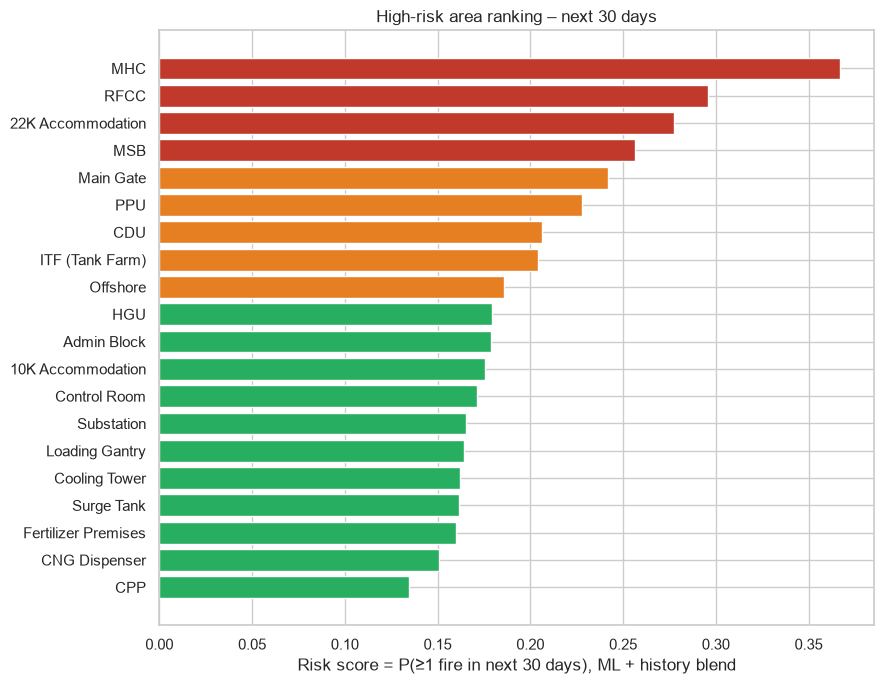

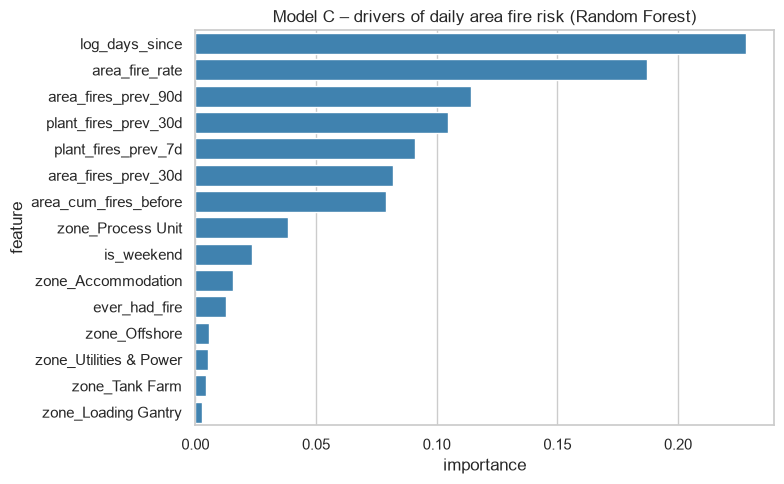

In [13]:
plt.figure(figsize=(9, 7))
pal = area_risk["risk_band"].map({"High": "#C0392B", "Medium": "#E67E22", "Low": "#27AE60"})
plt.barh(area_risk["area"][::-1], area_risk["risk_score_30d"][::-1], color=pal[::-1])
plt.xlabel("Risk score = P(≥1 fire in next 30 days), ML + history blend")
plt.title("High-risk area ranking – next 30 days")
plt.tight_layout(); plt.savefig(OUT_DIR / "charts" / "C_area_risk_ranking.png", dpi=130); plt.show()

imp_c = importance_table(final_all["Random Forest"], top=15)
plt.figure(figsize=(8, 5)); sns.barplot(data=imp_c, y="feature", x="importance", color="#2E86C1")
plt.title("Model C – drivers of daily area fire risk (Random Forest)")
plt.tight_layout(); plt.savefig(OUT_DIR / "charts" / "C_feature_importance.png", dpi=130); plt.show()

## 6. Scenario predictor – category probabilities for a hypothetical fire

In [14]:
best_pipe_a = models_a[best_a]
def predict_category(**kw):
    base = {c: "Unknown" for c in CAT_A} | {c: 0 for c in NUM_A}
    base.update(kw)
    p = best_pipe_a.predict_proba(pd.DataFrame([base])[CAT_A + NUM_A])[0]
    return pd.Series(p, index=le_a.classes_).sort_values(ascending=False).round(3)

predict_category(area="22K Accommodation", zone="Accommodation", equipment_type="Building structure",
                 fuel_type="Electrical", shift="Night (19-07)", time_band="Early Morning (00-06)", season="Rainy",
                 hour_sin=np.sin(2*np.pi*3/24), hour_cos=np.cos(2*np.pi*3/24))

BUILDING     0.943
3RD PARTY    0.029
EQUIPMENT    0.027
dtype: float32

## 7. Out-of-fold predictions per incident (for the dashboard)

In [15]:
inc_pred = inc[["incident_id", "incident_date", "area", "zone", "equipment_type", "primary_tag_base",
                "cause_category", "fire_nature", "severity_level"]].copy()
inc_pred["actual_category_model"] = y_a.values
inc_pred["pred_category_" + best_a.replace(" ", "_")] = le_a.inverse_transform(preds_a[best_a])
inc_pred["pred_confidence"] = probas_a[best_a].max(axis=1).round(3)
for i, c in enumerate(le_a.classes_):
    inc_pred[f"prob_{c}"] = probas_a[best_a][:, i].round(3)
inc_pred["nlp_pred_cause"] = le_nlp_cause.inverse_transform(p_nlp_cause)
inc_pred["correct"] = (inc_pred["actual_category_model"] == inc_pred["pred_category_" + best_a.replace(" ", "_")]).astype(int)
inc_pred.head()

,incident_id,incident_date,area,zone,equipment_type,primary_tag_base,cause_category,fire_nature,severity_level,actual_category_model,pred_category_XGBoost,pred_confidence,prob_3RD PARTY,prob_BUILDING,prob_EQUIPMENT,nlp_pred_cause,correct
0,FIRE-2026-001,2026-01-01,Loading Gantry,Loading Gantry,Vehicle,NaN,Vehicle fault,3RD PARTY,High,3RD PARTY,3RD PARTY,0.984,0.984,0.006,0.010,Vehicle fault,1
1,FIRE-2026-002,2026-01-06,RFCC,Process Unit,Heat exchanger / Heater,113-EE-1002,Pyrophoric,EQUIPMENT,Low,EQUIPMENT,EQUIPMENT,0.958,0.024,0.018,0.958,Other / Unknown,1
2,FIRE-2026-003,2026-01-13,MSB,Process Unit,Unknown,NaN,Hot work / Maintenance activity,EQUIPMENT,Low,EQUIPMENT,EQUIPMENT,0.953,0.022,0.025,0.953,Hot work / Maintenance activity,1
3,FIRE-2026-004,2026-01-22,MSB,Process Unit,Reactor,152-RB-1001,Flange / Seal leak,EQUIPMENT,Low,EQUIPMENT,EQUIPMENT,0.980,0.013,0.008,0.980,Other / Unknown,1
4,FIRE-2026-005,2026-01-24,CDU,Process Unit,Piping / Valve / Line,NaN,Hot work / Maintenance activity,EQUIPMENT,Low,EQUIPMENT,EQUIPMENT,0.958,0.025,0.017,0.958,Other / Unknown,1


## 8. EXPORT – models, predictions & report

In [16]:
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

def style_workbook(path):
    wb = load_workbook(path)
    for ws in wb.worksheets:
        for c in ws[1]:
            c.font = Font(name="Arial", bold=True, color="FFFFFF")
            c.fill = PatternFill("solid", start_color="7B241C")
            c.alignment = Alignment(wrap_text=True, vertical="center")
        for row in ws.iter_rows(min_row=2):
            for c in row:
                c.font = Font(name="Arial", size=10)
                if isinstance(c.value, float):
                    c.number_format = "0.000"
        ws.freeze_panes = "B2"; ws.auto_filter.ref = ws.dimensions
        for i, col in enumerate(ws.iter_cols(min_row=1, max_row=min(ws.max_row, 150)), 1):
            w = max(len(str(c.value)) if c.value is not None else 0 for c in col)
            ws.column_dimensions[get_column_letter(i)].width = min(max(10, w + 2), 55)
    wb.save(path)

def export_ml(out_dir=OUT_DIR):
    out_dir = Path(out_dir)
    stamp = datetime.now().strftime("%Y%m%d_%H%M")

    # 1) models
    joblib.dump({"pipeline": models_a[best_a], "label_encoder": le_a, "features": CAT_A + NUM_A, "model_name": best_a},
                out_dir / "model_A_fire_category.joblib")
    joblib.dump({"nature": nlp_nature, "nature_le": le_nlp_nature, "cause": nlp_cause, "cause_le": le_nlp_cause},
                out_dir / "model_B_nlp_text.joblib")
    joblib.dump({"pipelines": final_all, "features": CAT_C + NUM_C}, out_dir / "model_C_area_risk.joblib")

    # 2) report workbook
    summary = pd.DataFrame([
        ["Run date", datetime.now().strftime("%d-%b-%Y %H:%M")],
        ["Incidents used", len(inc)],
        ["Data period", f"{inc['incident_date'].min().date()} to {inc['incident_date'].max().date()}"],
        ["Model A best (category)", f"{best_a}  | F1-macro {res_a.loc[0,'f1_macro']:.2f} | Acc {res_a.loc[0,'accuracy']:.2f}"],
        ["Model B best (NLP cause)", f"{res_nlp_cause.loc[0,'model']} | F1-macro {res_nlp_cause.loc[0,'f1_macro']:.2f}"],
        ["Model C best (area risk)", f"{best_c} | ROC-AUC {res_c.set_index('model').loc[best_c,'ROC_AUC']:.2f}"],
        ["Forecast window", f"{(last_date + pd.Timedelta(days=1)).date()} to {(last_date + pd.Timedelta(days=HORIZON)).date()}"],
        ["Top-3 high-risk areas", ", ".join(area_risk.head(3)["area"])],
        ["Caution", "Small dataset (one year). Re-train monthly as new incidents are logged."],
    ], columns=["item", "value"])
    sheets = {
        "Summary": summary,
        "A_Model_Comparison": res_a,
        "A_Feature_Importance": imp_a,
        "B_NLP_Comparison": res_nlp,
        "B_Keywords_by_Cause": keywords_by_cause,
        "C_Model_Comparison": res_c,
        "C_Area_Risk_30d": area_risk,
        "C_Daily_Forecast": future[["date", "area", "zone", "p_Logistic Regression", "p_Random Forest", "p_XGBoost", "p_ensemble"]],
        "C_Feature_Importance": imp_c,
        "Incident_Predictions": inc_pred,
    }
    xlsx = out_dir / f"Fire_ML_Results_{stamp}.xlsx"
    with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
        for n, d in sheets.items():
            d.to_excel(xw, sheet_name=n[:31], index=False)
    style_workbook(xlsx)

    # 3) CSVs consumed by the dashboard notebook
    area_risk.to_csv(out_dir / "area_risk_30d.csv", index=False, encoding="utf-8-sig")
    future.to_csv(out_dir / "area_daily_forecast.csv", index=False, encoding="utf-8-sig")
    inc_pred.to_csv(out_dir / "incident_predictions.csv", index=False, encoding="utf-8-sig")
    pd.concat([res_a.assign(task="A – Category"), res_nlp.assign(task="B – NLP"), res_c.assign(task="C – Area risk")]) \
      .to_csv(out_dir / "model_metrics.csv", index=False, encoding="utf-8-sig")

    print("Exported to", out_dir.resolve())
    for p in sorted(out_dir.glob("*")):
        if p.is_file(): print("  ", p.name)
    return xlsx

ml_report = export_ml()

Exported to C:\Users\Work\Downloads\DDF_Project\fire_ml_output\fire_ml_models
   area_daily_forecast.csv
   area_risk_30d.csv
   Fire_ML_Results_20261104_0856.xlsx
   incident_predictions.csv
   model_A_fire_category.joblib
   model_B_nlp_text.joblib
   model_C_area_risk.joblib
   model_metrics.csv
